# The optical absorption of a defect, with no bands

How does a vacancy change the absorption of light by silicon? The absorption is the
real part of the optical conductivity $\sigma_{xx}(\omega)$. It counts the
transitions from occupied states at $E$ to empty states at $E + \hbar\omega$, each
weighted by the velocity matrix element between them. This is what ellipsometry
measures, through $\mathrm{Im}\,\epsilon(\omega) = 4\pi\,\mathrm{Re}\,\sigma(\omega)/\omega$.

A defect needs a supercell, and the usual sum over pairs of bands then needs
hundreds of empty bands. Here we compute the conductivity of a silicon supercell of
8 sites, with and without a vacancy, by the kernel polynomial method, so no band
is computed. For the perfect cell we compare with the sum over bands.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from defuqumat import Calculator

si = dict(pseudos={'Si': 'Si.pz-vbc.UPF'}, pseudo_dir='../tests/data/pseudo', ecut=163.3)
sites = [(0, 0, 0), (0, .5, .5), (.5, 0, .5), (.5, .5, 0), (.25, .25, .25), (.25, .75, .75), (.75, .25, .75), (.75, .75, .25)]
cells = {name: Calculator.from_keywords(lattice='cubic', a=5.43, atoms=[('Si', p) for p in atoms], kmesh=(2, 2, 2), smearing=0.1, **si)
         for name, atoms in (('perfect Si8', sites), ('Si8 with a vacancy', sites[1:]))}

## What is computed

The Kubo-Greenwood formula has no band index in it:

$$\mathrm{Re}\,\sigma_{ab}(\omega) = \frac{\pi}{\Omega\,\omega} \sum_{\mathbf k} w_{\mathbf k}
\int dE\, [f(E) - f(E + \omega)]\,
\mathrm{Tr}\left[v_b\, \delta(E - H)\, v_a\, \delta(E + \omega - H)\right].$$

Here $v_a = \partial H/\partial k_a$ is the velocity, which includes the nonlocal part
of the pseudopotential. We expand each $\delta(E - H)$ in Chebyshev polynomials of $H$,
so the trace becomes a matrix of moments
$\mu_{nm} = \mathrm{Tr}[v_b T_n(H) v_a T_m(H)]$. We estimate this trace with 4
random vectors per k-point, for the three directions, and we average
$\sigma_{xx}$, $\sigma_{yy}$ and $\sigma_{zz}$. The code also uses the atomic
orbitals, filtered to low energy: the transitions between the states they describe
are computed in that small space, and the random vectors carry only the rest, so
most of the noise is gone. The default kernel gives each
transition a Gaussian shape. The moments are kept, so the same result with the
Lorentz kernel, whose transitions are Lorentzians as in the sum over bands, costs
nothing more.

In [2]:
spectra = {}
for name, cell in cells.items():
    spectra[name] = cell.get_kpm_conductivity(broadening=0.02, n_random=4, window=0.6)
perfect = spectra['perfect Si8']
lorentz = perfect.reconstructed(kernel='lorentz')
band = cells['perfect Si8'].get_optical_conductivity(nbnd=56, broadening=perfect.broadening_for('lorentz'), intraband=False,
                                                     frequencies=perfect.frequencies[1:], fermi_energy=perfect.fermi_energy)

[defuqumat] a KPM optical conductivity: no ground state cached, running the SCF first (conv_thr = 1e-06). Call get_scf() to do this explicitly.


[defuqumat] a KPM optical conductivity: no ground state cached, running the SCF first (conv_thr = 1e-06). Call get_scf() to do this explicitly.


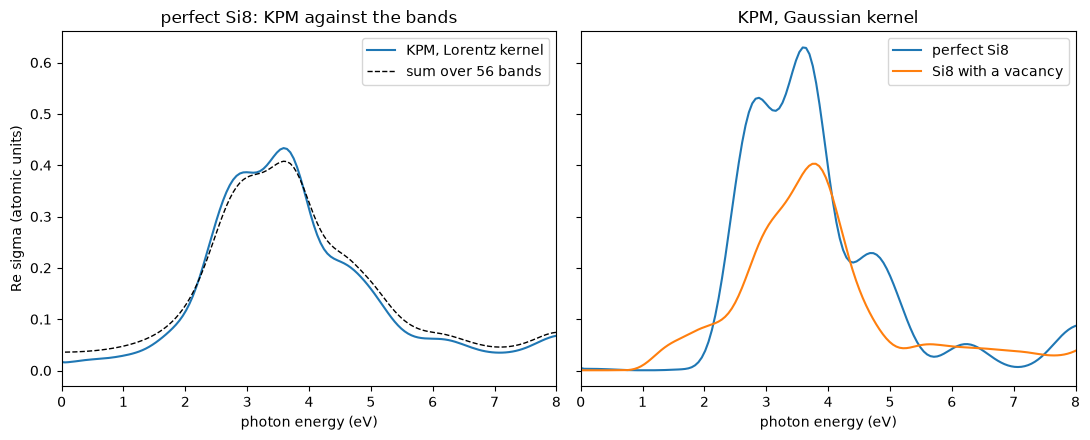

In [3]:
ev = 13.6057
average = lambda s: np.einsum('waa->w', s.real) / 3
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
left.plot(perfect.frequencies * ev, average(lorentz), label='KPM, Lorentz kernel')
left.plot(perfect.frequencies[1:] * ev, average(band.sigma), 'k--', lw=1, label='sum over 56 bands')
left.set_title('perfect Si8: KPM against the bands')
for name, s in spectra.items():
    right.plot(s.frequencies * ev, average(s.sigma), label=name)
right.set_title('KPM, Gaussian kernel')
for ax in (left, right):
    ax.set_xlabel('photon energy (eV)'); ax.set_xlim(0, 8); ax.legend()
left.set_ylabel('Re sigma (atomic units)')
plt.tight_layout()

On the left, the dashed line is the sum over pairs of bands for the perfect cell,
and the blue line is the KPM result for the same cell with Lorentzian
transitions. They have the same weight: between 1.5 and 6 eV the KPM curve holds 98
per cent of the weight of the band sum, and 99 per cent at half the broadening. The
KPM peak is about 6 per cent higher. This is the line shape and not the noise: the
Lorentz kernel gives a peak close to a Lorentzian but a little narrower at the top,
and at half the broadening the difference stays at 8 per cent. Below the absorption
edge the band sum is higher, because KPM occupies the states by energy after they are
broadened, so the part of a broadened state across the Fermi level is not counted.

On the right, with Gaussian transitions and so short tails, the absorption of the
perfect cell starts near 2 eV. With the vacancy it starts near 1 eV. These are
transitions to and from the states of the vacancy, which sit in the gap of the
perfect crystal. The main peak is lower, because one atom in eight is missing and
the remaining states lose part of their Bloch character.

In [4]:
for name, s in spectra.items():
    w, a = s.frequencies * ev, average(s.sigma)
    low = (w > 0.5) & (w < 1.8)
    print(f'{name:20s} peak {a.max():.3f} at {w[np.argmax(a)]:.2f} eV,  weight from 0.5 to 1.8 eV {np.trapezoid(a[low], w[low]):.4f}')
print(f'perfect Si8 peak with the Lorentz kernel {average(lorentz).max():.3f}, sum over bands {average(band.sigma).max():.3f}')

perfect Si8          peak 0.629 at 3.59 eV,  weight from 0.5 to 1.8 eV 0.0017
Si8 with a vacancy   peak 0.403 at 3.80 eV,  weight from 0.5 to 1.8 eV 0.0369
perfect Si8 peak with the Lorentz kernel 0.433, sum over bands 0.408


Between 0.5 and 1.8 eV the vacancy gives about twenty times the weight of the
perfect cell, and the peak moves up by about 0.2 eV and drops by a third. These
numbers do not depend on the random vectors: with other seeds, or with 16 vectors
instead of 4, the peaks change by less than 0.1 per cent. Note that 8 k-points of a cell of 8 sites are
few, so the peaks are not converged.

For this small cell the bands are cheap, and the sum over bands is faster. The
method is for large supercells of a dilute defect or of disorder, where the sum over
bands needs thousands of empty bands. The checks of these numbers are in
`tests/unit/test_kpm_conductivity.py`: the moments against the eigenvectors of the
dense Hamiltonian, and the conductivity against the sum over the same pairs of
states.